# Health Data Explorer — Starter Notebook

Das ist dein Ausgangspunkt für das Projekt. Alles, was du zum Start brauchst, ist unten vorbereitet: der Datensatz ist geladen, die Helper-Funktionen sind definiert, und es gibt eine Platzhalterzelle für jede Frage.

Deine Aufgabe: die Platzhalterzellen durch deinen Code ersetzen, Markdown-Erklärungen darum herum schreiben und ein vollständiges Analyse-Notebook erstellen.

Lies den Setup-Abschnitt einmal durch, dann geht es weiter zu Frage 1.

## Setup

Führe die Zellen in diesem Abschnitt aus, bevor du irgendetwas anderes machst.

In [1]:
# Standard-Imports für Datenanalyse und Visualisierung
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Farbpalette für alle Charts: Blau als Hauptfarbe, Grafit/Violett/Grau als Ergänzung,
# Rot nur für "ungünstig"
BLUE, GRAPHITE, VIOLET, GRAY, RED = '#0071E3', '#3A3A3C', '#8E4EC6', '#A1A1A6', '#B3261E'

# Ein einheitliches Erscheinungsbild für alle Charts
sns.set_theme(style='whitegrid', palette=[BLUE, GRAPHITE, VIOLET, GRAY, RED])
plt.rcParams['figure.dpi'] = 100

In [2]:
# Chart-Styling-Helfer — sorgt für ein einheitliches Erscheinungsbild aller Plots in diesem Notebook
FIGSIZE = (8, 5)
GENDER_COLORS = {'M': BLUE, 'F': VIOLET}
SMOKER_COLORS = {'Yes': GRAPHITE, 'No': GRAY}  # neutral: Rauchen ist hier kein "Problem-Befund"
# Activity Level ist eine geordnete Kategorie -> Blau-Abstufung von hell (Sedentary) nach dunkel (Very Active)
ACTIVITY_COLORS = ['#7DB5F2', '#3E8FE8', '#1C69C8', '#0A3F85']

def finalize_plot(ax, title, xlabel, ylabel):
    ax.set_title(title, fontsize=13, pad=12)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    plt.tight_layout()

def fmt_de(x, decimals=1, suffix=''):
    """Zahl mit deutschem Format: Tausenderpunkt, Dezimalkomma."""
    s = f"{x:,.{decimals}f}".replace(',', 'X').replace('.', ',').replace('X', '.')
    return s + suffix

def add_bar_labels(ax, decimals=1, suffix='', scale=1, padding=3):
    """Schreibt den Wert über jede Säule und lässt oben etwas Platz, damit nichts abgeschnitten wird."""
    for c in ax.containers:
        labels = [fmt_de(b.get_height() * scale, decimals, suffix) if np.isfinite(b.get_height()) else ''
                  for b in c]
        ax.bar_label(c, labels=labels, padding=padding, fontsize=10)
    ax.margins(y=0.15)

def label_bars(ax, labels, fontsize=10):
    """Eigene Beschriftung je Säule, von links nach rechts (unabhängig davon, wie Seaborn die Säulen gruppiert)."""
    bars = sorted((p for p in ax.patches if p.get_width() > 0), key=lambda p: p.get_x())
    for p, label in zip(bars, labels):
        ax.annotate(label, (p.get_x() + p.get_width() / 2, p.get_height()), ha='center', va='bottom',
                    xytext=(0, 3), textcoords='offset points', fontsize=fontsize)
    ax.margins(y=0.15)

In [3]:
# Datensatz laden
# (In Colab: liegt die CSV nicht im Arbeitsordner, öffnet sich ein Upload-Dialog — health_data_processed.csv auswählen.)
from pathlib import Path
if not Path('health_data_processed.csv').exists():
    try:
        from google.colab import files
        files.upload()
    except ImportError:
        raise FileNotFoundError("health_data_processed.csv muss im selben Ordner wie das Notebook liegen.")
df = pd.read_csv('health_data_processed.csv')

# Kurzer Blick — sicherstellen, dass alles korrekt geladen wurde
print(f"Zeilen: {len(df):,}")
print(f"Spalten: {list(df.columns)}")
df.head()

Zeilen: 50,002
Spalten: ['Height', 'Weight', 'Gender', 'Age', 'Activity_Level', 'Smoker', 'BMI', 'bmi_category', 'BF%', 'message', 'bf_healthy']


,Height,Weight,Gender,Age,Activity_Level,Smoker,BMI,bmi_category,BF%,message,bf_healthy
0,1.62,53.80,F,19,Sedentary,No,20.50,Normal weight,23.57,Great work – your BMI is in the healthy range!...,True
1,1.72,76.12,M,56,Lightly Active,No,25.73,Overweight,27.56,Your BMI is in the overweight range. Aim for g...,False
2,1.80,87.38,M,69,Sedentary,No,26.97,Overweight,32.03,Your BMI is in the overweight range. Aim for g...,False
3,1.80,74.28,M,20,Very Active,No,22.93,Normal weight,15.92,Great work – your BMI is in the healthy range!...,True
4,1.63,62.76,F,54,Lightly Active,No,23.62,Normal weight,35.36,Great work – your BMI is in the healthy range!...,False


### Die Helper-Funktionen

Vier Funktionen sind bereits für dich vordefiniert. Du wirst sie im gesamten Projekt verwenden, meist über `df.apply(...)`. Lies jede einzelne, bevor du sie benutzt — verstehe, was sie erwartet und was sie zurückgibt.

In [4]:
def calculate_bmi(weight_kg, height_m):
    """BMI = weight in kg divided by height in metres squared."""
    return weight_kg / (height_m ** 2)


def categorize_bmi(bmi):
    """Returns the standard WHO BMI category for a given BMI value."""
    if bmi < 18.5:
        return 'Underweight'
    elif bmi < 25:
        return 'Normal weight'
    elif bmi < 30:
        return 'Overweight'
    else:
        return 'Obese'


def calculate_body_fat(bmi, age, gender):
    """Body fat % using the Deurenberg formula. Gender is 'M' or 'F'."""
    gender_factor = 1 if gender == 'M' else 0
    return 1.20 * bmi + 0.23 * age - 10.8 * gender_factor - 5.4


# Healthy BF% ranges by age bracket and gender
# Each entry is (lower_bound, upper_bound), both inclusive
healthy_bf_ranges = {
    '18-29': {'M': (9, 20),    'F': (19, 28)},
    '30-39': {'M': (11, 21),   'F': (21.5, 29)},
    '40-49': {'M': (13, 22),   'F': (24, 31)},
    '50-59': {'M': (16, 24),   'F': (25, 33)},
    '60+':   {'M': (19, 25),   'F': (28, 35)},
}


def healthy_bf(row):
    """Returns True if the person's BF% falls in the healthy range for
    their age bracket and gender. Expects a row with Age, Gender, BF%."""
    age = row['Age']
    if age <= 29:
        bracket = '18-29'
    elif age <= 39:
        bracket = '30-39'
    elif age <= 49:
        bracket = '40-49'
    elif age <= 59:
        bracket = '50-59'
    else:
        bracket = '60+'

    lo, hi = healthy_bf_ranges[bracket][row['Gender']]
    return lo <= row['BF%'] <= hi

### Über den Datensatz

Du arbeitest mit Gesundheitsdaten von 50.000 Menschen: ihrer Körpergröße, ihrem Gewicht, Alter, Geschlecht, Aktivitätslevel und Raucherstatus. Vier Spalten wurden bereits mit den obigen Helper-Funktionen berechnet: `BMI`, `bmi_category`, `BF%` (Körperfettanteil) und `bf_healthy` (ein Boolean aus `healthy_bf()`).

**Nimm dir jetzt einen Moment, um die Daten zu inspizieren**, bevor du irgendeine Frage beantwortest. Prüfe die Form, die Spalten, die Datentypen, die eindeutigen Werte jeder kategorialen Spalte. Echte EDA beginnt immer hier.

In [5]:
# Form, Datentypen, fehlende Werte, Duplikate
print(f"Form: {df.shape}")
print(df.dtypes)
print("\nFehlende Werte pro Spalte:")
print(df.isna().sum())
print("\nExakte Duplikat-Zeilen:", df.duplicated().sum())

df.describe()

Form: (50002, 11)
Height            float64
Weight            float64
Gender             object
Age                 int64
Activity_Level     object
Smoker             object
BMI               float64
bmi_category       object
BF%               float64
message            object
bf_healthy           bool
dtype: object

Fehlende Werte pro Spalte:
Height            0
Weight            0
Gender            0
Age               0
Activity_Level    0
Smoker            0
BMI               0
bmi_category      0
BF%               0
message           0
bf_healthy        0
dtype: int64

Exakte Duplikat-Zeilen: 96


,Height,Weight,Age,BMI,BF%
count,50002.000000,50002.000000,50002.000000,50002.000000,50002.000000
mean,1.687936,67.350444,49.068297,23.504162,28.433026
std,0.098895,11.207017,18.213459,2.280985,7.425406
min,1.450000,45.000000,18.000000,15.840000,8.690000
25%,1.620000,59.080000,33.000000,21.930000,22.930000
50%,1.680000,66.570000,49.000000,23.440000,28.410000
75%,1.760000,75.020000,65.000000,25.000000,33.650000
max,2.000000,111.330000,80.000000,34.460000,51.030000


In [6]:
# Kategoriale Spalten — nach Auffälligkeiten suchen
for col in ['Gender', 'Activity_Level', 'Smoker', 'bmi_category']:
    print(df[col].value_counts())
    print()

Gender
M    26194
F    23808
Name: count, dtype: int64

Activity_Level
Lightly Active       17596
Sedentary            16956
Moderately Active    11621
Very Active           3828
Moderate                 1
Name: count, dtype: int64

Smoker
No     43641
Yes     6361
Name: count, dtype: int64

bmi_category
Normal weight    37022
Overweight       12352
Underweight        458
Obese              170
Name: count, dtype: int64



In [7]:
# Gegenprobe zu den 96 Duplikaten: Sind exakte Duplikate häufiger als "Fast-Duplikate"
# (gleiche Person, nur 1 Jahr älter)? Wenn nicht, spricht das für Zufall statt Doppelerfassung.
key = ['Height', 'Weight', 'Gender', 'Age', 'Activity_Level', 'Smoker']
exact = df[key].duplicated().sum()
combos = df[key].drop_duplicates()
near = len(combos.merge(combos.assign(Age=combos['Age'] + 1), on=key))
print(f"Exakte Duplikate: {exact} | Fast-Duplikate (nur 1 Jahr Altersunterschied): {near}")

Exakte Duplikate: 96 | Fast-Duplikate (nur 1 Jahr Altersunterschied): 199


In [8]:
# "Moderate" taucht als 5. Activity_Level-Wert mit nur einer Zeile auf — fast
# sicher ein Tippfehler für "Moderately Active" (siehe Notiz unten). Wird
# umkodiert statt gelöscht, da es nur 1 Zeile von 50.002 betrifft und Löschen
# Information ohne echten Nutzen vernichten würde.
n_moderate = (df['Activity_Level'] == 'Moderate').sum()
df['Activity_Level'] = df['Activity_Level'].replace('Moderate', 'Moderately Active')
print(f"{n_moderate} Zeile(n) von 'Moderate' zu 'Moderately Active' umkodiert.")
df['Activity_Level'].value_counts()

1 Zeile(n) von 'Moderate' zu 'Moderately Active' umkodiert.


Activity_Level
Lightly Active       17596
Sedentary            16956
Moderately Active    11622
Very Active           3828
Name: count, dtype: int64

**Was bei der Inspektion auffiel:**

Auf den ersten Blick wirkt der Datensatz sauber — 50.002 Zeilen, 11 Spalten, keine fehlenden Werte irgendwo — aber zwei Dinge fielen auf, sobald ich über die Kopfzahlen hinausgeschaut habe. Erstens gibt es 96 exakte Duplikat-Zeilen (0,19% der Daten): Zeilen, die in allen Spalten mit einer anderen Zeile übereinstimmen (88 Paare und 4 Dreiergruppen). Das wirkt auf den ersten Blick verdächtig, ist aber vermutlich Zufall: Größe und Gewicht sind auf zwei Nachkommastellen gerundet, und Zeilen, die sich nur um 1 Jahr im Alter unterscheiden, gibt es sogar häufiger (siehe Gegenprobe oben) als exakte Duplikate — es gibt also kein Muster, das auf eine Doppelerfassung hindeutet. Ich habe die Zeilen deshalb gezählt und dokumentiert, aber nicht gelöscht: Sind es echte, unterschiedliche Personen, würde Löschen reale Beobachtungen vernichten, und bei 0,19% ändert sich an den Ergebnissen ohnehin nichts. Zweitens ist `Activity_Level` nicht das saubere Vier-Kategorien-Feld, das ich erwartet hatte: neben Sedentary, Lightly Active, Moderately Active und Very Active gab es eine einzelne Zeile mit dem Wert "Moderate" — fast sicher ein abgeschnittener oder falsch eingegebener Eintrag für "Moderately Active", den ich oben umkodiert statt gelöscht habe. Die übrigen Wertebereiche (Age 18–80, BMI 15,84–34,46, BF% 8,69–51,03) sind alle physiologisch plausibel, und Gender ist recht ausgeglichen (26.194 M vs. 23.808 F), sodass der Datensatz so verwendbar ist. Ein Punkt, den man später im Hinterkopf behalten sollte: `bmi_category` ist stark zu Normal weight (74,0%) und Overweight (24,7%) verschoben, während Underweight (0,9%) und besonders Obese (0,3%, nur 170 Personen) sehr kleine Gruppen sind — jeder Vergleich, der die Daten auf diese Kategorien einschränkt, basiert auf einer deutlich dünneren Stichprobe und sollte mit dieser Einschränkung gelesen werden.

Ein fünfter `Activity_Level`-Wert, der nur in einer einzigen isolierten Zeile auftaucht, ist eher ein Warnsignal als eine echte Kategorie — die vier offiziellen Level sind eine feste, bewusst benannte Menge, und "Moderate" passt zu nah in dieses Muster, um wirklich ein neues Label zu sein. Da es genau 1 von 50.002 Zeilen betrifft (0,002% der Daten), war Umkodieren statt Löschen die vertretbarere Entscheidung — eine Zeile zu löschen vernichtet Information für einen vernachlässigbaren Gewinn an "Sauberkeit", während Umkodieren die Beobachtung unter der Annahme erhält, die am besten zur Beweislage passt. Die Korrektur hier explizit zu dokumentieren, statt sie stillschweigend einzuarbeiten, bedeutet, dass jeder, der dieses Notebook prüft, die getroffene Annahme sehen und ihr widersprechen kann, falls eine andere Interpretation von "Moderate" passender erscheint.

Eine dritte Beobachtung betrifft die Datengrundlage: `BF%` ist keine Messung, sondern wird mit `calculate_body_fat()` (Deurenberg-Formel) aus BMI, Alter und Geschlecht berechnet: 1,2 × BMI + 0,23 × Alter − 10,8 × (Mann) − 5,4. Dadurch steigt der Körperfettanteil mit dem Alter fast automatisch (+0,23 Punkte pro Jahr), und `bf_healthy` vergleicht ihn mit Grenzen, die ebenfalls nach Alter und Geschlecht gestaffelt sind. Das ist bei allen Ergebnissen zum Körperfett im Hinterkopf zu behalten.

---

## Teil 1 — Geführte Fragen

Sieben Fragen sind zu beantworten. Schreibe für jede Frage eine kurze Markdown-Zelle, die erklärt, was du tust und warum, führe deinen Code aus, und schreibe danach eine schriftliche Interpretation dessen, was das Ergebnis zeigt.

---

### Frage 1 — BMI Category Distribution by Gender

Gib die Gesamtanzahlen und Prozentsätze von Männern und Frauen über die BMI-Kategorien hinweg an. Notiere alle Unterschiede zwischen den Geschlechtern und visualisiere die Ergebnisse mit Seaborn, wie du es am sinnvollsten findest.

Anzahl:
 bmi_category  Normal weight  Obese  Overweight  Underweight
Gender                                                     
F                     19690     18        3779          321
M                     17332    152        8573          137

Prozent innerhalb jedes Geschlechts:
 bmi_category  Normal weight  Obese  Overweight  Underweight
Gender                                                     
F                      82.7    0.1        15.9          1.3
M                      66.2    0.6        32.7          0.5


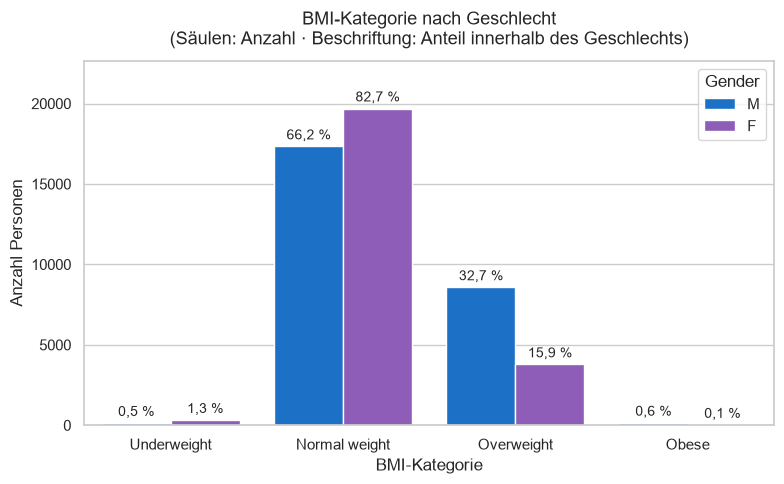

In [9]:
counts = pd.crosstab(df['Gender'], df['bmi_category'])
pct = pd.crosstab(df['Gender'], df['bmi_category'], normalize='index').mul(100).round(1)
print("Anzahl:\n", counts)
print("\nProzent innerhalb jedes Geschlechts:\n", pct)

order = ['Underweight', 'Normal weight', 'Overweight', 'Obese']
fig, ax = plt.subplots(figsize=FIGSIZE)
sns.countplot(data=df, x='bmi_category', hue='Gender', order=order, hue_order=['M', 'F'],
              palette=GENDER_COLORS, ax=ax)
# Über jeder Säule steht der Anteil innerhalb des jeweiligen Geschlechts
# (Reihenfolge von links nach rechts: je Kategorie erst M, dann F)
label_bars(ax, [fmt_de(pct.loc[g, cat], 1, ' %') for cat in order for g in ['M', 'F']])
finalize_plot(ax, 'BMI-Kategorie nach Geschlecht\n(Säulen: Anzahl · Beschriftung: Anteil innerhalb des Geschlechts)',
              'BMI-Kategorie', 'Anzahl Personen')
plt.show()

**Deine Interpretation:**

Männer fallen etwa doppelt so häufig in die Kategorie Overweight wie Frauen (32,7% vs. 15,9%), und die Lücke wird bei Obesity noch größer, wo die Rate bei Männern etwa sechsmal so hoch ist (0,6% vs. 0,1%). Entsprechend sind Frauen viel stärker im Normal-weight-Bereich konzentriert (82,7% vs. 66,2% bei Männern) — insgesamt zeigt sich also eine Verschiebung der männlichen BMI-Verteilung nach rechts, kein isolierter Ausreißer in einer einzelnen Kategorie. Man sollte hier aber vorsichtig sein: Die Obese- und Underweight-Gruppen sind insgesamt recht klein (zusammen unter 2% der Stichprobe), ihre Prozentwerte beruhen also nur auf einigen hundert Personen und sind entsprechend unsicherer als der Normal/Overweight-Vergleich. Dieses Muster sagt zudem nichts darüber aus, *warum* der Geschlechterunterschied besteht — Faktoren wie unterschiedliche Muskelmasse, Lebensstil oder wie BMI selbst berechnet wird, könnten alle eine Rolle spielen, und die Daten allein können das nicht trennen.

---

### Frage 2 — Average Body Fat Percentage by Activity Level

Gruppiere die Daten nach `Activity_Level` und berechne den Mittelwert von `BF%` für jede Gruppe. Welches Activity Level ist mit dem niedrigsten durchschnittlichen Körperfettanteil verbunden? Überrascht dich das Ergebnis?

Visualisiere die Ergebnisse mit Seaborn, wie du es am sinnvollsten findest.

                    mean   std  count
Activity_Level                       
Sedentary          29.60  7.31  16956
Lightly Active     28.54  7.33  17596
Moderately Active  27.20  7.41  11622
Very Active        26.51  7.44   3828


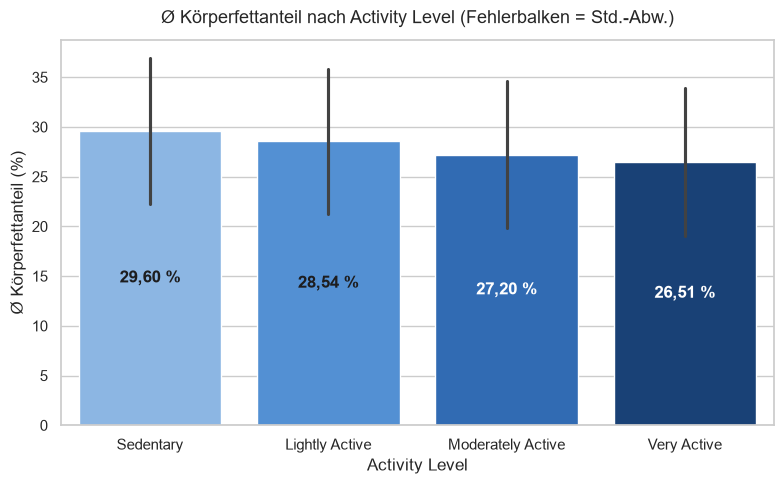

In [10]:
activity_order = ['Sedentary', 'Lightly Active', 'Moderately Active', 'Very Active']
q2 = df.groupby('Activity_Level')['BF%'].agg(['mean', 'std', 'count']).round(2).reindex(activity_order)
print(q2)

fig, ax = plt.subplots(figsize=FIGSIZE)
sns.barplot(data=df, x='Activity_Level', y='BF%', order=activity_order, errorbar='sd',
            hue='Activity_Level', palette=dict(zip(activity_order, ACTIVITY_COLORS)), legend=False, ax=ax)
# Mittelwert in die Säule geschrieben (über den Säulen liegen die Fehlerbalken)
for i, level in enumerate(activity_order):
    ax.text(i, q2.loc[level, 'mean'] / 2, fmt_de(q2.loc[level, 'mean'], 2, ' %'), ha='center', va='center',
            fontsize=12, fontweight='bold', color='white' if i >= 2 else '#1D1D1F')
finalize_plot(ax, 'Ø Körperfettanteil nach Activity Level (Fehlerbalken = Std.-Abw.)', 'Activity Level', 'Ø Körperfettanteil (%)')
plt.show()

In [11]:
# Gegenprobe: Ø Körperfettanteil nach Activity Level, getrennt nach Altersgruppe (Alter konstant gehalten)
df['Altersgruppe'] = pd.cut(df['Age'], bins=[17, 29, 39, 49, 59, 120], labels=['18-29', '30-39', '40-49', '50-59', '60+'])
q2_alter = df.groupby(['Altersgruppe', 'Activity_Level'], observed=True)['BF%'].mean().round(2).unstack()[activity_order]
print(q2_alter)
print("\nØ Alter je Activity Level:", df.groupby('Activity_Level')['Age'].mean().round(1).reindex(activity_order).to_dict())

Activity_Level  Sedentary  Lightly Active  Moderately Active  Very Active
Altersgruppe                                                             
18-29               21.42           21.61              21.38        21.54
30-39               24.01           23.78              24.03        23.68
40-49               26.64           26.81              26.77        27.17
50-59               29.89           29.70              29.70        30.05
60+                 34.68           34.64              34.60        34.78

Ø Alter je Activity Level: {'Sedentary': 53.1, 'Lightly Active': 49.6, 'Moderately Active': 44.8, 'Very Active': 41.7}


**Deine Interpretation:**

Der durchschnittliche Körperfettanteil sinkt gleichmäßig mit steigendem Activity Level, von 29,60% bei Sedentary bis 26,51% bei Very Active — ein Unterschied von etwa 3 Prozentpunkten, der sich gleichmäßig über die vier Stufen verteilt statt sich in einem einzelnen Sprung zu konzentrieren. Auffällig ist, dass die Standardabweichung über alle vier Gruppen hinweg fast identisch bleibt (rund 7,3–7,4) — das bedeutet, es handelt sich um eine Verschiebung des typischen Werts, nicht um eine Veränderung der Streuung innerhalb der jeweiligen Activity-Level-Gruppe. Eingeordnet: Ein Unterschied von 3 Punkten auf einer Skala mit einer Standardabweichung von über 7 ist eher moderat — und die Gegenprobe oben zeigt, dass er größtenteils nicht von der Aktivität selbst kommt: Sedentary-Personen sind im Schnitt über 11 Jahre älter als Very-Active-Personen (53,1 gegenüber 41,7 Jahre), und der Körperfettanteil wird in diesem Datensatz per Formel berechnet (aus BMI, Alter und Geschlecht, mit 0,23 Punkten pro Lebensjahr). Hält man das Alter konstant, liegen die vier Activity-Level innerhalb jeder Altersgruppe nur um etwa 0,1 bis 0,5 Punkte auseinander, ohne klare Richtung. Der Zusammenhang im Gesamtvergleich ist also ein Alters-Effekt, kein Aktivitäts-Effekt.

---

### Frage 3 — Smokers vs Non-Smokers: who has healthier body fat?

Berechne mithilfe der Spalte `bf_healthy` den Prozentsatz der Menschen mit gesundem BF% getrennt für Raucher und Nichtraucher. Was legt die Datenlage über die Beziehung zwischen Rauchen und Körperfettgesundheit nahe?

Smoker
No     38.8
Yes    40.2
Name: bf_healthy, dtype: float64


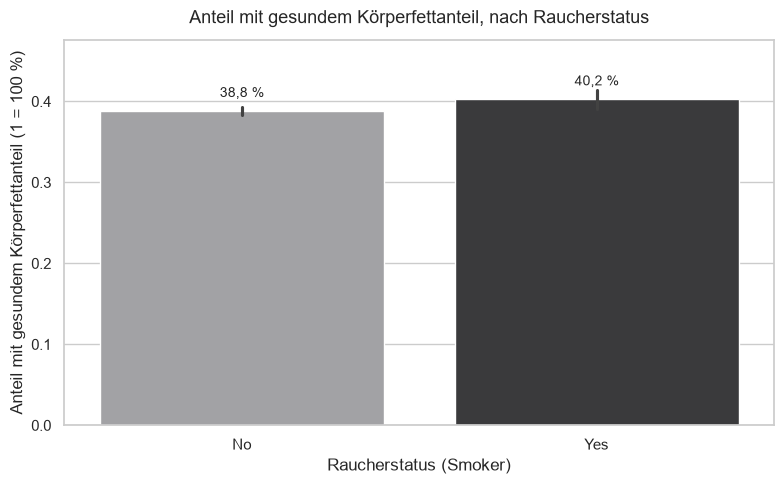

In [12]:
q3 = df.groupby('Smoker')['bf_healthy'].mean().mul(100).round(1)
print(q3)

fig, ax = plt.subplots(figsize=FIGSIZE)
sns.barplot(data=df, x='Smoker', y='bf_healthy', order=['No', 'Yes'], hue='Smoker',
            palette=SMOKER_COLORS, legend=False, ax=ax)
add_bar_labels(ax, decimals=1, suffix=' %', scale=100, padding=8)
finalize_plot(ax, 'Anteil mit gesundem Körperfettanteil, nach Raucherstatus', 'Raucherstatus (Smoker)', 'Anteil mit gesundem Körperfettanteil (1 = 100 %)')
plt.show()

**Deine Interpretation:**

Etwas kontraintuitiv haben Raucher sogar eine leicht höhere Rate an gesundem Körperfettanteil als Nichtraucher (40,2% vs. 38,8%) — das widerspricht der naheliegenden Annahme, dass Rauchen mit schlechteren Werten bei der Körperzusammensetzung einhergehen würde. Der Unterschied beträgt nur 1,4 Prozentpunkte, und die Rauchergruppe ist deutlich kleiner als die Nichtrauchergruppe (6.361 vs. 43.641) — das sollte also nicht als Beleg dafür gelesen werden, dass Rauchen irgendwie vorteilhaft ist, sondern deutet bestenfalls auf einen sehr schwachen oder gar keinen Zusammenhang zwischen Raucherstatus und gesundem Körperfett in diesem Datensatz hin. Wichtig: Dies ist ein Rohvergleich ohne Kontrolle für andere Variablen wie Alter oder Activity Level, die einen echten Zusammenhang leicht verdecken oder verzerren könnten — es lässt sich daraus keine Kausalität in irgendeine Richtung ableiten.

---

### Frage 4 — BMI distribution among people over 45

Filtere den Datensatz so, dass nur Menschen älter als 45 enthalten sind. Wende deine Funktion `categorize_bmi()` an, um ihre BMI-Kategorien zu bestätigen, und visualisiere die Verteilung der rohen BMI-Werte. Wie schneidet diese Gruppe im Vergleich zum gesamten Datensatz ab?

**Tipp:** Du kannst `plt.subplots(1, 2)` verwenden, um zwei Plots nebeneinander zu platzieren.

n über 45: 27,845 von 50,002

BMI gesamt:
 count    50002.000000
mean        23.504162
std          2.280985
min         15.840000
25%         21.930000
50%         23.440000
75%         25.000000
max         34.460000
Name: BMI, dtype: float64

BMI über 45:
 count    27845.000000
mean        24.157426
std          2.279284
min         16.140000
25%         22.590000
50%         24.110000
75%         25.680000
max         34.460000
Name: BMI, dtype: float64


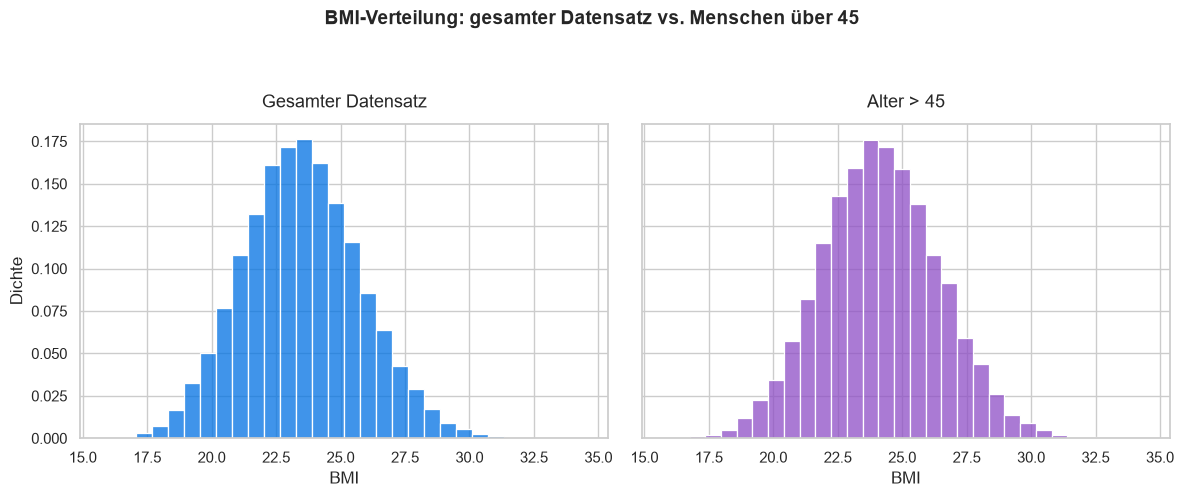

In [13]:
over45 = df[df['Age'] > 45].copy()
over45['bmi_category_check'] = over45['BMI'].apply(categorize_bmi)
assert (over45['bmi_category_check'] == over45['bmi_category']).all()  # bestätigt, dass categorize_bmi mit der vorberechneten Spalte übereinstimmt

print(f"n über 45: {len(over45):,} von {len(df):,}")
print("\nBMI gesamt:\n", df['BMI'].describe())
print("\nBMI über 45:\n", over45['BMI'].describe())

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
sns.histplot(df['BMI'], bins=30, stat='density', color=BLUE, ax=axes[0])
sns.histplot(over45['BMI'], bins=30, stat='density', color=VIOLET, ax=axes[1])
finalize_plot(axes[0], 'Gesamter Datensatz', 'BMI', 'Dichte')
finalize_plot(axes[1], 'Alter > 45', 'BMI', 'Dichte')
# Gesamttitel oberhalb der beiden Teilplot-Titel, mit Abstand (kein Überlappen)
fig.suptitle('BMI-Verteilung: gesamter Datensatz vs. Menschen über 45', fontsize=14, fontweight='bold', y=0.99)
fig.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

**Deine Interpretation:**

Bei Menschen über 45 steigt der Ø-BMI um etwa 0,66 Punkte im Vergleich zur Gesamtstichprobe (23,50 auf 24,16), und der Anteil im Normal-weight-Bereich sinkt von 74,0% auf 64,5% — der Großteil dieser Verschiebung wandert in die Overweight-Kategorie (24,7% auf 34,4%). Bemerkenswert: Die Standardabweichung ist in beiden Gruppen praktisch unverändert (2,28 in beiden Fällen), was darauf hindeutet, dass es sich um eine einheitliche Verschiebung des BMI-Niveaus in der älteren Bevölkerung handelt, nicht darum, dass die Gruppe einfach variabler oder uneinheitlicher wird. Das passt zu einem allgemeinen Trend steigenden BMIs mit dem Alter, aber der Vergleich allein belegt Alter nicht als Ursache — Faktoren wie reduzierte Aktivität, Muskelabbau oder altersbedingte Stoffwechselveränderungen könnten hier alle eine Rolle spielen und sind nicht isoliert betrachtet.

---

### Frage 5 — Gender × Smoking: a combined view

Berechne den mittleren BMI und den mittleren Körperfettanteil für jede Kombination aus Geschlecht und Raucherstatus. Welche Kombination hat den höchsten durchschnittlichen Körperfettanteil, und welche den niedrigsten durchschnittlichen BMI?

Verwende `.groupby()` — keine Einzelberechnungen.

Visualisiere dein Ergebnis als Seaborn-`barplot` des mittleren BF% mit Geschlecht auf der x-Achse und Raucherstatus als `hue`.

                 BMI    BF%
Gender Smoker              
F      No      22.87  33.37
       Yes     22.78  33.17
M      No      24.10  24.00
       Yes     23.99  23.73

Höchster Ø-BF%: ('F', 'No') -> 33.37
Niedrigster Ø-BMI: ('F', 'Yes') -> 22.78


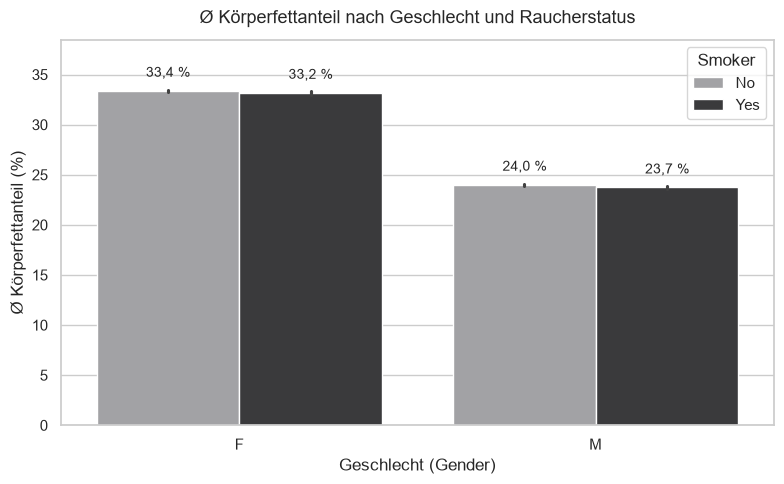

In [14]:
q5 = df.groupby(['Gender', 'Smoker'])[['BMI', 'BF%']].mean().round(2)
print(q5)
print("\nHöchster Ø-BF%:", q5['BF%'].idxmax(), "->", q5['BF%'].max())
print("Niedrigster Ø-BMI:", q5['BMI'].idxmin(), "->", q5['BMI'].min())

fig, ax = plt.subplots(figsize=FIGSIZE)
sns.barplot(data=df, x='Gender', y='BF%', hue='Smoker', order=['F', 'M'], hue_order=['No', 'Yes'],
            palette=SMOKER_COLORS, ax=ax)
add_bar_labels(ax, decimals=1, suffix=' %', padding=8)
finalize_plot(ax, 'Ø Körperfettanteil nach Geschlecht und Raucherstatus', 'Geschlecht (Gender)', 'Ø Körperfettanteil (%)')
plt.show()

**Deine Interpretation:**

Wenn man BMI und Körperfettanteil nach Geschlecht und Raucherstatus aufschlüsselt, erzählen die beiden Metriken je nach Blickwinkel fast gegensätzliche Geschichten: Frauen haben einen niedrigeren Ø-BMI als Männer (etwa 22,8 gegenüber 24,0), aber einen deutlich höheren Ø-Körperfettanteil (rund 33% gegenüber 24%). Das ist kein Widerspruch in den Daten oder ein Beleg dafür, dass Frauen "ungesünder" wären — es spiegelt einen gut dokumentierten biologischen Unterschied in der Körperzusammensetzung wider, bei dem Frauen bei gleichem BMI natürlicherweise mehr Körperfett tragen. Die beiden Indikatoren sind also nicht austauschbar: Der Körperfettanteil wird hier per Formel berechnet und berücksichtigt zusätzlich das Geschlecht (Männer −10,8 Punkte), das der BMI ignoriert. Innerhalb jedes Geschlechts bewegt der Raucherstatus kaum eine der beiden Zahlen: Der Unterschied zwischen Rauchern und Nichtrauchern bleibt bei BMI und BF% jeweils unter 0,3 Punkten. Diese Lücke ist klein genug, um als Hintergrundrauschen statt als bedeutsames Muster zu gelten — das Geschlecht, nicht der Raucherstatus, ist hier der dominante Faktor. Insgesamt mahnen die Ergebnisse zur Vorsicht davor, "Gesundheit" mit einer einzigen Zahl zusammenzufassen, da BMI und BF% je nach betrachteter Population deutlich auseinanderlaufen können.

---

### Frage 6 — Sedentary people and body fat health

Filtere den Datensatz auf ausschließlich sedentary Personen. Verwende `.apply()`, um deine Funktion `healthy_bf()` zeilenweise auf diese Gruppe anzuwenden, und berichte den Prozentsatz mit gesundem Körperfettanteil, aufgeschlüsselt nach Geschlecht.

Sind sedentary Männer oder Frauen eher in einem gesunden BF%-Bereich?

**Visualisierung:** ein Seaborn-`countplot`, der die Counts für gesunden vs. ungesunden BF% zeigt, aufgeteilt nach Geschlecht mit `hue`.

Gender
F    30.5
M    35.1
Name: Healthy_BF, dtype: float64

Zeilen, bei denen der neu berechnete Wert von bf_healthy abweicht: 3 von 16956


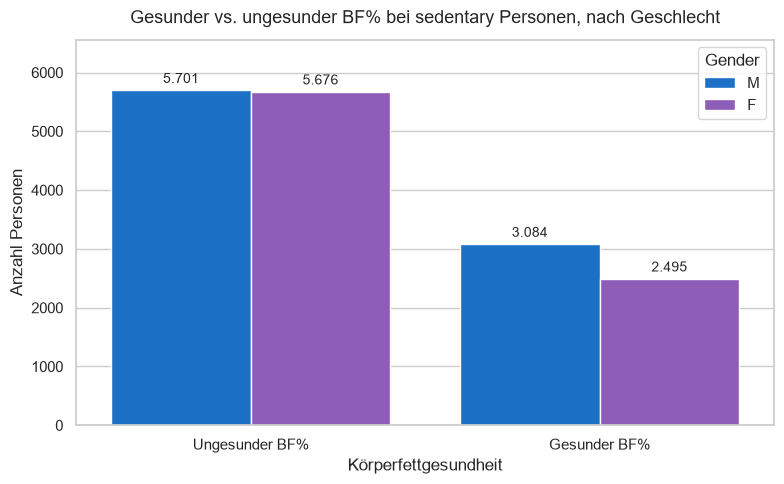

In [15]:
sedentary = df[df['Activity_Level'] == 'Sedentary'].copy()
sedentary['Healthy_BF'] = sedentary.apply(healthy_bf, axis=1)

pct_healthy = sedentary.groupby('Gender')['Healthy_BF'].mean().mul(100).round(1)
print(pct_healthy)

# Kurzer Gegencheck: stimmt der neu berechnete Wert mit der vorberechneten Spalte bf_healthy überein?
mismatches = (sedentary['Healthy_BF'] != sedentary['bf_healthy']).sum()
print(f"\nZeilen, bei denen der neu berechnete Wert von bf_healthy abweicht: {mismatches} von {len(sedentary)}")

fig, ax = plt.subplots(figsize=FIGSIZE)
sns.countplot(data=sedentary, x='Healthy_BF', hue='Gender', order=[False, True], palette=GENDER_COLORS, ax=ax)
add_bar_labels(ax, decimals=0)
ax.set_xticks([0, 1])
ax.set_xticklabels(['Ungesunder BF%', 'Gesunder BF%'])
finalize_plot(ax, 'Gesunder vs. ungesunder BF% bei sedentary Personen, nach Geschlecht', 'Körperfettgesundheit', 'Anzahl Personen')
plt.show()

**Deine Interpretation:**

Bei sedentary Personen (16.956 Menschen: 8.171 Frauen und 8.785 Männer) liegt ein spürbar größerer Anteil der Männer als der Frauen im jeweils eigenen gesunden Körperfett-Bereich — 35,1% der sedentary Männer gegenüber 30,5% der sedentary Frauen, eine Lücke von 4,6 Prozentpunkten. Das sollte nicht so gelesen werden, dass sedentary Männer insgesamt "gesünder" wären als sedentary Frauen, denn die gesunden BF%-Bänder sind je nach Geschlecht unterschiedlich kalibriert (zum Beispiel gilt für 18–29-Jährige bei Männern etwa 9–20%, bei Frauen 19–28%) — die beiden Prozentwerte messen also, wie jede Gruppe an ihrem eigenen, separaten Maßstab abschneidet, nicht an einem gemeinsamen, identischen Schwellenwert. Erwähnenswert ist außerdem ein kurzer Datenqualitäts-Check, der bei dieser Analyse mitgelaufen ist: Das Neuberechnen des Healthy-BF%-Flags mit `.apply()`, statt der vorberechneten `bf_healthy`-Spalte blind zu vertrauen, ergab 3 von 16.956 Zeilen in dieser Teilmenge, bei denen beide Werte nicht übereinstimmten (alle direkt am Rand des Bereichs) — viel zu wenig, um die berichteten Prozentwerte zu beeinflussen, aber eine gute Erinnerung daran, ein neu berechnetes Ergebnis gegenzuprüfen, statt eines der beiden blind zu übernehmen.

---

### Frage 7 — Health metrics across age groups

Das Dictionary `healthy_bf_ranges` definiert fünf Altersklammern: 18–29, 30–39, 40–49, 50–59 und 60+. Filtere den Datensatz mithilfe von Boolean Indexing in diese fünf Gruppen und berechne für jede:

- Ø BMI
- Ø BF%
- Anteil der Menschen mit gesundem BF%

Füge die Ergebnisse zu einem Summary-DataFrame zusammen und zeige ihn an. Wie entwickeln sich die Gesundheitsmetriken mit zunehmendem Alter?

**Visualisierung:** ein Seaborn-`lineplot` mit der Altersgruppe auf der x-Achse, der sowohl Ø BMI als auch Ø BF% als zwei separate Linien zeigt.

              Mean_BMI  Std_BMI  Mean_BF  Std_BF  Pct_Healthy_BF      n
Altersgruppe                                                           
18-29            22.65     2.00    21.48    5.27           81.54   9524
30-39            22.65     1.99    23.91    5.24           62.54   7859
40-49            22.94     2.03    26.78    5.30           43.33   7957
50-59            23.54     2.10    29.80    5.33           28.96   7931
60+              24.64     2.27    34.66    5.58            6.38  16731


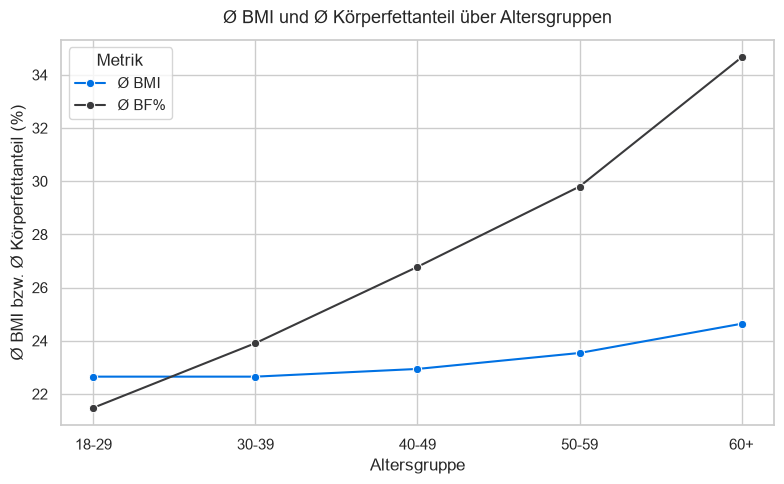

In [16]:
bins = [17, 29, 39, 49, 59, 120]
labels = ['18-29', '30-39', '40-49', '50-59', '60+']
df['Altersgruppe'] = pd.cut(df['Age'], bins=bins, labels=labels)

q7 = df.groupby('Altersgruppe', observed=True).agg(
    Mean_BMI=('BMI', 'mean'), Std_BMI=('BMI', 'std'),
    Mean_BF=('BF%', 'mean'), Std_BF=('BF%', 'std'),
    Pct_Healthy_BF=('bf_healthy', lambda s: s.mean() * 100),
    n=('BMI', 'count'),
).round(2)
print(q7)

q7_long = q7.reset_index().melt(id_vars='Altersgruppe', value_vars=['Mean_BMI', 'Mean_BF'],
                                  var_name='Metrik', value_name='Wert')
q7_long['Metrik'] = q7_long['Metrik'].replace({'Mean_BMI': 'Ø BMI', 'Mean_BF': 'Ø BF%'})
fig, ax = plt.subplots(figsize=FIGSIZE)
sns.lineplot(data=q7_long, x='Altersgruppe', y='Wert', hue='Metrik', marker='o', ax=ax)
finalize_plot(ax, 'Ø BMI und Ø Körperfettanteil über Altersgruppen', 'Altersgruppe', 'Ø BMI bzw. Ø Körperfettanteil (%)')
plt.show()

**Deine Interpretation:**

Der Ø-BMI bleibt über die drei jüngsten Altersgruppen fast konstant (22,65 sowohl bei 18–29 als auch bei 30–39, dann 22,94 bei 40–49), bevor er in den 50ern spürbarer steigt (23,54) und in der 60+-Gruppe weiter zulegt (24,64). Da sich die Standardabweichung über alle fünf Gruppen kaum verändert (zwischen 2,00 und 2,27), handelt es sich um eine Verschiebung des typischen BMI-Niveaus mit dem Alter, nicht um eine wachsende Uneinheitlichkeit innerhalb der Gruppen — die Population wird nicht variabler, sie liegt im Schnitt nur höher. Das auffälligste Ergebnis in diesem Vergleich ist jedoch, wie stark der Anteil mit "gesundem" BF% mit dem Alter einbricht: von 81,5% in der 18–29-Gruppe auf nur noch 6,4% in der 60+-Gruppe — ein weit steilerer Rückgang, als der moderate BMI-Trend allein vermuten lassen würde. Die wahrscheinliche Erklärung: Der Ø-BF% steigt kontinuierlich und deutlich mit dem Alter (von 21,48% auf 34,66%, über 13 Punkte), während die gesunden BF%-Referenzbänder pro Altersgruppe nur leicht nach oben angepasst sind — der tatsächliche Anstieg des Körperfetts mit dem Alter überholt also die Anpassung der "gesunden" Schwelle, wodurch zunehmend mehr Menschen aus dem gesunden Band herausfallen, obwohl sich ihr BMI nur moderat verschiebt. Dieses Muster ist ein altersbezogener Zusammenhang in den Daten, kein Beweis dafür, dass das Altern diese Veränderungen isoliert verursacht, da Faktoren wie Activity Level, Muskelmasse und Stoffwechsel plausible Confounder sind. Ein Vorbehalt: Die 60+-Gruppe ist zugleich die größte Stichprobe und deckt eine breitere Altersspanne ab (60–80 Jahre) als die sauberen Zehn-Jahres-Bänder der anderen Gruppen — das sollte man beim direkten Vergleich im Hinterkopf behalten.

---

## Teil 2 — Deine eigenen Fragen

Drei eigene Fragen zum Datensatz. Jede muss sich **wirklich unterscheiden** von den sieben oben — nicht einfach dieselbe Frage mit einer ausgetauschten Spalte.

Damit du eher zu nützlichen als zu einfachen Fragen kommst, muss jede deiner drei Fragen eine der folgenden Einschränkungen erfüllen. Wähle pro Frage eine Einschränkung, insgesamt drei unterschiedliche.

1. **Cross-categorical:** kombiniert mindestens zwei kategoriale Gruppierungen, die die geführten Fragen nicht kombiniert haben (zum Beispiel: Activity Level × Altersklammer, Gender × Altersklammer × Smoking).
2. **Text-basiert:** nutzt die Spalte `message` auf irgendeine Weise — zum Beispiel Gruppierung oder Filterung basierend auf dem enthaltenen Gesundheitsrat.
3. **Begründet:** kommt mit einer kurzen schriftlichen Begründung, *warum diese Frage wichtig ist*, bevor der Code kommt. Die Einschränkung betrifft hier die Framing/Argumentation, nicht die Technik.

Für jede Frage:

- Schreibe die Frage als Markdown-Zelle und gib an, welche Einschränkung sie erfüllt.
- Schreibe den Code.
- Erzeuge eine Visualisierung.
- Schreibe eine kurze Interpretation.

---

### Deine Frage 1

**Frage:**

Wie unterscheidet sich der durchschnittliche BMI zwischen den `Activity_Level`-Gruppen, wenn man die Personen zusätzlich in Altersgruppen aufteilt (z. B. 18–30, 31–45, 46–60, 60+)? Bleibt der BMI-Vorteil von "Very Active" auch in höheren Altersgruppen bestehen, oder gleicht er sich mit zunehmendem Alter an?

**Constraint:** 1 — Cross-categorical. Kombiniert `Activity_Level` mit einer neu gebildeten Altersgruppen-Spalte — eine Kombination, die keine der 7 geführten Fragen verwendet hat.

Altersgruppe       18-29  30-39  40-49  50-59    60+
Activity_Level                                      
Lightly Active     22.73  22.69  22.96  23.54  24.64
Moderately Active  22.62  22.68  22.98  23.59  24.59
Sedentary          22.61  22.58  22.86  23.51  24.64
Very Active        22.61  22.63  23.05  23.70  24.87


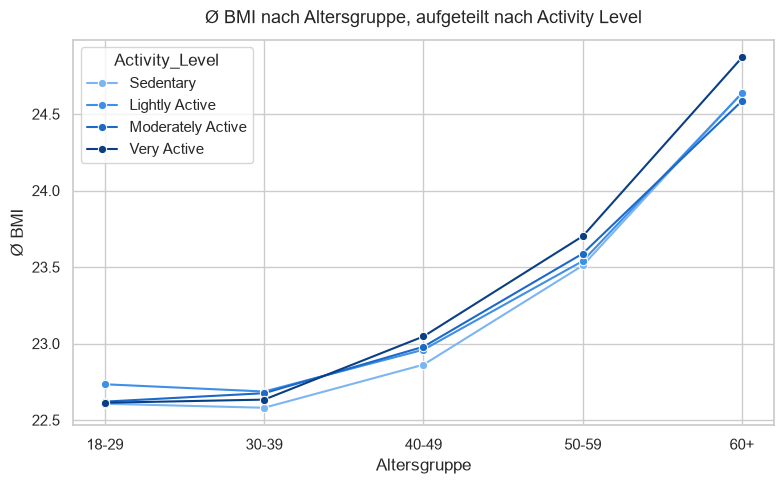

In [17]:
own1 = df.groupby(['Activity_Level', 'Altersgruppe'], observed=True)['BMI'].mean().round(2).unstack()
print(own1)

fig, ax = plt.subplots(figsize=FIGSIZE)
sns.lineplot(data=df, x='Altersgruppe', y='BMI', hue='Activity_Level', hue_order=activity_order,
             palette=dict(zip(activity_order, ACTIVITY_COLORS)), marker='o', errorbar=None, ax=ax)
finalize_plot(ax, 'Ø BMI nach Altersgruppe, aufgeteilt nach Activity Level', 'Altersgruppe', 'Ø BMI')
plt.show()

**Deine Interpretation:**

Teilt man den Ø-BMI sowohl nach Altersgruppe als auch nach Activity Level auf, zeigt sich ein Ergebnis, das der ursprünglichen Hypothese widerspricht: Innerhalb einer einzelnen Altersklammer unterscheiden sich die vier Activity-Level-Stufen nur um etwa 0,1 bis 0,2 BMI-Punkte — zum Beispiel liegt in der 40-49-Gruppe Sedentary bei 22,86 gegenüber Very Active bei 23,05, ein Unterschied, der neben dem Messrauschen vernachlässigbar ist. Der Alterseffekt dagegen ist deutlich größer: Der Ø-BMI steigt von rund 22,6 in der 18-29-Gruppe auf etwa 24,7 in der 60+-Gruppe — eine Verschiebung, die um ein Vielfaches größer ist als jeder Activity-Level-Unterschied. Das bedeutet: Die Daten stützen die Erwartung nicht, dass "Very Active"-Personen mit dem Alter deutlich schlanker bleiben — zumindest nicht gemessen am BMI. Wichtig ist, genau zu sagen, was das NICHT zeigt: Es bedeutet nicht, dass körperliche Aktivität keinen gesundheitlichen Wert hat — der Datensatz enthält nur Momentaufnahmen, und der Körperfettanteil darin wird per Formel aus BMI, Alter und Geschlecht berechnet, kann also gar nicht direkt auf Aktivität reagieren (der Unterschied in Frage 2 war ein Alters-Effekt). Es bedeutet konkret, dass der BMI kaum auf Activity Level reagiert, sobald man das Alter berücksichtigt. Nicht Aktivität, sondern Alter ist der dominante Treiber der BMI-Unterschiede zwischen diesen Gruppen.

---

### Deine Frage 2

**Frage:**

Enthalten die personalisierten Nachrichten (`message`) von Personen mit ungesundem Körperfettanteil (`bf_healthy == False`) häufiger Formulierungen wie "consult" oder "doctor" als die Nachrichten von Personen mit gesundem BF%?

**Constraint:** 2 — Text-basiert. Nutzt die Spalte `message` über eine Schlüsselwortsuche, kombiniert mit der bestehenden `bf_healthy`-Spalte.

bf_healthy
False    0.6
True     0.0
Name: message, dtype: float64

Eindeutige message-Vorlagen im gesamten Datensatz: 4
bmi_category
Normal weight    Great work – your BMI is in the healthy range!...
Obese            Your BMI falls in the obese range. Consulting ...
Overweight       Your BMI is in the overweight range. Aim for g...
Underweight      Your BMI suggests you are underweight. Conside...
Name: message, dtype: object


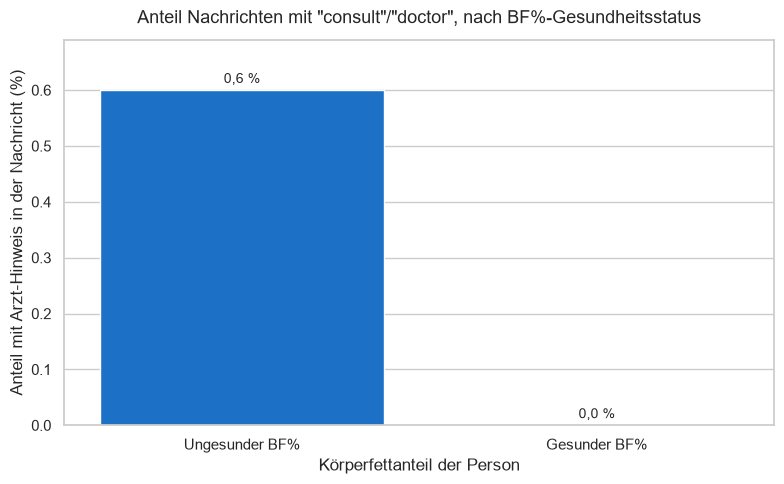

In [18]:
has_keyword = df['message'].str.contains('consult', case=False, na=False) | df['message'].str.contains('doctor', case=False, na=False)
pct_by_health = has_keyword.groupby(df['bf_healthy']).mean().mul(100).round(1)
print(pct_by_health)

print("\nEindeutige message-Vorlagen im gesamten Datensatz:", df['message'].nunique())
print(df.groupby('bmi_category', observed=True)['message'].apply(lambda s: s.iloc[0][:60] + '...'))

fig, ax = plt.subplots(figsize=FIGSIZE)
sns.barplot(x=pct_by_health.index.map({True: 'Gesunder BF%', False: 'Ungesunder BF%'}), y=pct_by_health.values,
            color=BLUE, ax=ax)
add_bar_labels(ax, decimals=1, suffix=' %')
finalize_plot(ax, 'Anteil Nachrichten mit "consult"/"doctor", nach BF%-Gesundheitsstatus',
              'Körperfettanteil der Person', 'Anteil mit Arzt-Hinweis in der Nachricht (%)')
plt.show()

**Deine Interpretation:**

Auf den ersten Blick wirkt das nach einem dramatischen Muster: Nur 0,6% der Personen mit ungesundem Körperfettanteil bekommen eine Nachricht mit "consult" oder "doctor", gegenüber 0,0% bei Personen mit gesundem BF%. Bevor man das als Befund stehen lässt, lohnt sich ein Blick darauf, woher diese Schlüsselwörter überhaupt kommen: Die gesamte `message`-Spalte besteht aus nur 4 eindeutigen Vorlagen im ganzen Datensatz — eine pro `bmi_category` — und nur die "Obese"-Vorlage enthält "Consulting a doctor..." (170 Personen insgesamt, was exakt der Obese-Anzahl entspricht; selbst die Underweight-Vorlage vermeidet das Wort und spricht stattdessen von "healthcare provider"). Die 0,6%-Zahl misst also etwas engeres, als es zunächst aussieht: Von den 30.509 Personen mit ungesundem BF% bekommt nur der winzige Anteil, der *zusätzlich* BMI-Obese ist, überhaupt eine Arzt-Empfehlung in der Nachricht — die übrigen 99,4% der BF%-ungesunden Personen bekommen keine solche Empfehlung, einfach weil ihr BMI die Obese-Schwelle nicht überschreitet. Das ist die eigentliche Erkenntnis hier, und es ist kein Sprach- oder Kommunikationsbefund — es ist ein Beleg dafür, dass ein rein BMI-basiertes Nachrichtensystem fast alle Personen übersieht, deren Körperfettanteil echten Anlass zur Sorge gibt, es sei denn, ihr BMI ist extrem genug, um zusätzlich als Obese zu gelten. Das heißt nicht, dass die Nachrichtenlogik für die Obese-Gruppe selbst "falsch" wäre (hier hat tatsächlich jede Obese-Person auch einen ungesunden BF%, das passt zusammen) — die Lücke liegt speziell bei der viel größeren Gruppe von Personen, deren BMI noch als normal oder nur übergewichtig gilt, ein Thema, das in Deiner Frage 3 direkt aufgegriffen wird.

---

### Deine Frage 3

**Frage:**

Wie groß ist der Anteil an Personen, die laut BMI im Bereich "Normal weight" liegen, aber laut Körperfettanteil trotzdem als ungesund gelten (`bmi_category == "Normal weight"` und `bf_healthy == False`, umgangssprachlich "skinny fat")?

**Warum diese Frage wichtig ist:** Diese Gruppe wird von rein BMI-basierten Gesundheits-Screenings übersehen, obwohl sie laut Körperfettanteil gesundheitlich gefährdet sein könnte. Das zeigt, dass BMI allein kein ausreichendes Diagnosekriterium ist — relevant für jede Beratung oder Kampagne, die sich nur auf den BMI stützt.

**Constraint:** 3 — Begründet ("Justified"). Die Argumentation oben begründet die Relevanz der Frage, bevor der Code kommt.

Normal weight, aber ungesunder BF% ('skinny fat'): 18,343 von 37,022 Normal-weight-Personen (49.5%)
Das sind 36.7% des gesamten Datensatzes.


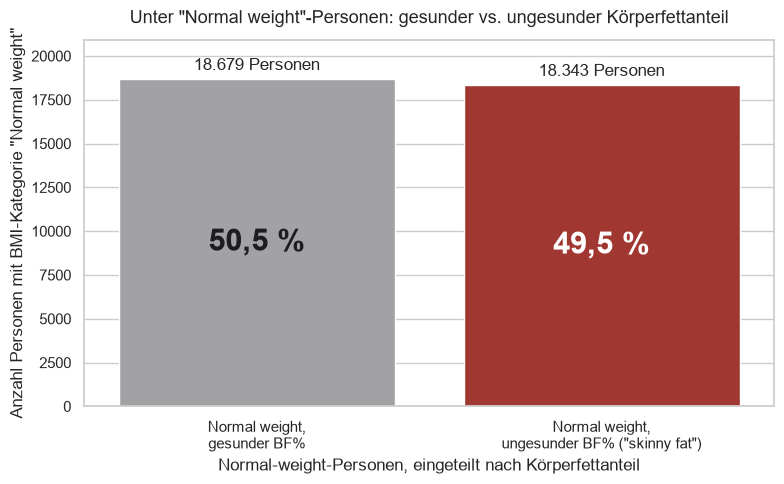

In [19]:
normal = df[df['bmi_category'] == 'Normal weight']
skinny_fat = normal[normal['bf_healthy'] == False]
pct_of_normal = len(skinny_fat) / len(normal) * 100
pct_of_all = len(skinny_fat) / len(df) * 100
print(f"Normal weight, aber ungesunder BF% ('skinny fat'): {len(skinny_fat):,} von {len(normal):,} "
      f"Normal-weight-Personen ({pct_of_normal:.1f}%)")
print(f"Das sind {pct_of_all:.1f}% des gesamten Datensatzes.")

summary = pd.DataFrame({
    'group': ['Normal weight,\ngesunder BF%', 'Normal weight,\nungesunder BF% ("skinny fat")'],
    'count': [len(normal) - len(skinny_fat), len(skinny_fat)]
})
fig, ax = plt.subplots(figsize=FIGSIZE)
sns.barplot(data=summary, x='group', y='count', hue='group', palette=[GRAY, RED], legend=False, ax=ax)
# Über jeder Säule: Anzahl und Anteil an allen Normal-weight-Personen
# Anzahl über jedem Balken, Anteil (in %) in der Mitte des Balkens
bars = sorted((p for p in ax.patches if p.get_width() > 0), key=lambda p: p.get_x())
for p, n, text_color in zip(bars, summary['count'], ['#1D1D1F', 'white']):
    x = p.get_x() + p.get_width() / 2
    ax.annotate(f"{fmt_de(n, 0)} Personen", (x, p.get_height()), ha='center', va='bottom',
                xytext=(0, 4), textcoords='offset points', fontsize=12)
    ax.text(x, p.get_height() / 2, fmt_de(n / len(normal) * 100, 1, ' %'), ha='center', va='center',
            fontsize=22, fontweight='bold', color=text_color)
ax.margins(y=0.12)
finalize_plot(ax, 'Unter "Normal weight"-Personen: gesunder vs. ungesunder Körperfettanteil', 'Normal-weight-Personen, eingeteilt nach Körperfettanteil', 'Anzahl Personen mit BMI-Kategorie "Normal weight"')
plt.show()

**Deine Interpretation:**

Von den 37.022 Personen, die laut BMI als "Normal weight" eingestuft sind, haben 18.343 — 49,5%, also praktisch jede Zweite — trotzdem einen für ihr Alter und Geschlecht ungesunden Körperfettanteil, ein Muster, das oft "skinny fat" genannt wird. In absoluten Zahlen entspricht diese Gruppe 36,7% der gesamten 50.002-Personen-Stichprobe — mehr als ein Drittel aller Personen im Datensatz würde also hören, ihr Gewicht sei "normal", obwohl ihre Körperzusammensetzung tatsächlich als ungesund eingestuft wird. Das ist ein substanzieller Befund, kein Randfall: Er zeigt, dass ein rein BMI-basierter Screening-Ansatz — wie das in Deiner Frage 2 untersuchte Nachrichtensystem — etwa 18.300 Personen fälschlich beruhigen würde, die von genauerer Aufmerksamkeit profitieren könnten. Genauso wichtig ist zu sagen, was das NICHT beweist: Es bedeutet nicht, dass BMI insgesamt ein nutzloses oder kaputtes Maß ist, da BMI und Körperfettanteil im breiteren Datensatz, der in früheren Fragen untersucht wurde, durchaus korreliert bleiben. Es zeigt vielmehr, dass die mittlere BMI-Kategorie "Normal weight" eine breite, wenig verstandene Grauzone enthält, in der die beiden Messsysteme auseinanderlaufen — und dass es riskant ist, sich für diese Gruppe allein auf BMI zu verlassen, weil dabei echtes Gesundheitssignal verloren geht, das der Körperfettanteil erfassen würde.

---

## Teil 3 — Zusammenfassung

Beende dein Notebook mit einem kurzen schriftlichen Zusammenfassungs-Abschnitt. Kein Code nötig.

In ein oder zwei kurzen Absätzen:

- Was sind die **drei interessantesten Erkenntnisse**, die du in den Daten gefunden hast?
- Gab es etwas, das dich **überrascht** hat oder dem widersprochen hat, was du erwartet hattest?
- Was würdest du als Nächstes untersuchen, wenn du mehr Zeit hättest?

Dieser Abschnitt ist wichtig. Datenanalyse ist nur nützlich, wenn du kommunizieren kannst, was du herausgefunden hast.

---

_Viel Erfolg — und viel Freude beim Erkunden._

**Deine Zusammenfassung:**

Das auffälligste Muster in dieser Analyse ist, wie oft BMI und Körperfettanteil auseinanderlaufen — und wie sehr diese Lücke zählt. Etwa die Hälfte aller laut BMI "Normal weight"-Personen (49,5%, rund 18.300 Menschen) hat tatsächlich einen für ihr Alter und Geschlecht ungesunden Körperfettanteil — ein "skinny fat"-Muster, das ein reiner BMI-Check komplett übersieht, und das auch das eigene Nachrichtensystem dieses Datensatzes übersieht, da es nur bei der kleinen Obese-BMI-Gruppe Alarm schlägt. Ein zweites klares Muster zeigt sich beim Alter: Während der Ø-BMI von den 20ern bis in die 60er nur moderat steigt, bricht der Anteil mit gesundem Körperfettanteil von 81,5% in der 18–29-Gruppe auf nur noch 6,4% in der 60+-Gruppe ein, weil der Körperfettanteil weiter steigt, lange nachdem die altersangepassten "gesunden" Bänder sich kaum noch bewegen. Drittens erweist sich Geschlecht als weit stärkerer Faktor als Rauchen oder Activity Level für die meisten Metriken — Frauen tragen bei niedrigerem Ø-BMI deutlich mehr Körperfett als Männer, rein als Frage der Körperzusammensetzung, nicht des Gesundheitszustands (dieser Unterschied steckt bereits in der Formel, die den Körperfettanteil berechnet).

Am meisten überrascht hat mich, wie wenig sich der BMI durch das Activity Level bewegen lässt, sobald man das Alter konstant hält — die vier Activity-Level-Gruppen unterscheiden sich innerhalb einer Altersklammer nur um 0,1–0,2 BMI-Punkte, und auch der scheinbare Unterschied von 3 Punkten beim Körperfettanteil zwischen Sedentary und Very Active verschwindet, sobald man das Alter konstant hält (sedentary Personen sind im Schnitt über 11 Jahre älter). Ich hatte erwartet, dass sich ein aktiverer Lebensstil in jedem Alter als niedrigerer BMI zeigt, und das passiert in diesem Datensatz schlicht nicht. Beim Körperfettanteil ist zu beachten, dass er hier per Formel aus BMI, Alter und Geschlecht berechnet wird: Er ist keine unabhängige Messung, sondern berücksichtigt zusätzlich Alter und Geschlecht, die der BMI ignoriert — genau daraus entstehen die Unterschiede zwischen beiden. Auch Rauchen war als Prädiktor wenig überzeugend — Raucher zeigten keine schlechteren (wenn überhaupt, leicht bessere) BF%- und BMI-Werte als Nichtraucher, was vermutlich mehr über die kleine Rauchergruppe und nicht gemessene Confounder aussagt als über das Rauchen selbst. Mit mehr Zeit würde ich Alter und Activity Level gleichzeitig kontrollieren (z. B. mit einer einfachen Regression), um zu sehen, ob der Raucheffekt dann weiterhin null bleibt, prüfen, ob die 96 exakten Duplikate Doppelerfassungen oder Zufallstreffer sind (die Gegenprobe mit Fast-Duplikaten spricht für Zufall), und ein kombiniertes "Risiko-Flag" bauen, das BF% statt BMI-Kategorie nutzt, um zu sehen, wie viele Menschen das aktuelle Nachrichtensystem gerade übersieht.

## Practice

Zwei zusätzliche Fragen, um den EDA-Workflow zu üben, bevor die bewerteten Projektfragen oben angegangen werden. Kein Teil der offiziellen Abgabe — nur Übung.

---

### Practice-Frage 1 — Geschlecht und durchschnittliche Körpergröße

Gibt es einen auffälligen Unterschied in der durchschnittlichen Körpergröße zwischen Männern und Frauen in diesem Datensatz? Wie groß ist der Unterschied, und ist die Streuung in beiden Gruppen ähnlich?

        mean    std  count
Gender                    
F       1.62  0.069  23808
M       1.75  0.079  26194

Mittlerer Unterschied: 13.0 cm (Männer größer)


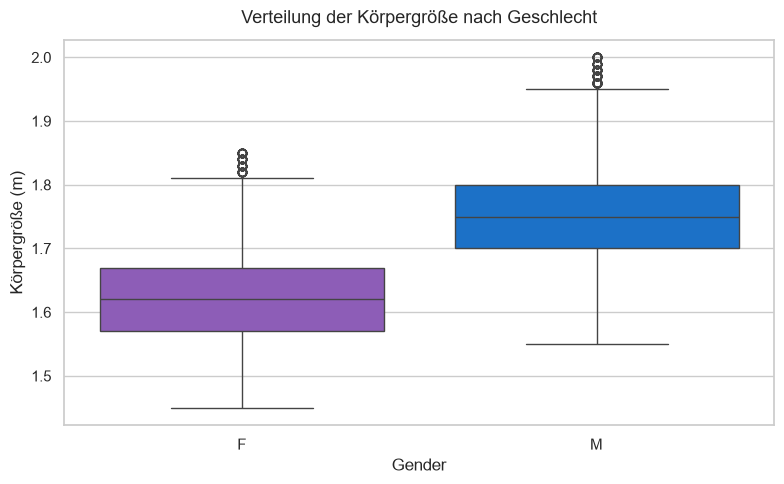

In [20]:
p1 = df.groupby('Gender')['Height'].agg(['mean', 'std', 'count']).round(3)
print(p1)
print(f"\nMittlerer Unterschied: {(p1.loc['M','mean'] - p1.loc['F','mean'])*100:.1f} cm (Männer größer)")

fig, ax = plt.subplots(figsize=FIGSIZE)
sns.boxplot(data=df, x='Gender', y='Height', order=['F', 'M'], hue='Gender', palette=GENDER_COLORS, legend=False, ax=ax)
finalize_plot(ax, 'Verteilung der Körpergröße nach Geschlecht', 'Gender', 'Körpergröße (m)')
plt.show()

**Interpretation:**

Männer sind in diesem Datensatz größer als Frauen, aber der Unterschied ist eine Verschiebung der Mitte der Verteilung, kein Beleg dafür, dass die beiden Gruppen in getrennten Welten leben. Der durchschnittliche Unterschied beträgt 13,0 cm (175,0 cm bei Männern vs. 162,0 cm bei Frauen), ein realer und recht großer Effekt nach anthropometrischen Maßstäben — vergleichbar mit dem, was echte Bevölkerungsstudien zur Körpergröße berichten — sodass es angesichts der beteiligten Stichprobengrößen (23.808 Frauen, 26.194 Männer) kaum Zufall sein kann. Was die Zahlen nicht zeigen, ist ein Unterschied in der Streuung der beiden Gruppen: Die Standardabweichung liegt bei 7,9 cm für Männer und 6,9 cm für Frauen — nah genug beieinander, dass dies keine Divergenz in der Variabilität ist, sondern zwei ähnlich geformte Verteilungen, die etwa 13 cm auseinanderliegen. Das bedeutet auch, dass sich die beiden Verteilungen deutlich überlappen — viele einzelne Frauen sind größer als viele einzelne Männer — es handelt sich also um eine Aussage über Gruppen-Durchschnitte, nicht um eine Regel für eine einzelne Person.

---

### Practice-Frage 2 — Activity Level bei Menschen unter 30

Gefiltert auf Menschen im Alter von 18–29: Wie sieht die Aufschlüsselung des Activity Levels im Vergleich zur Aufschlüsselung im gesamten Datensatz aus?

                   Gesamt %  Unter 30 %
Activity_Level                         
Sedentary              33.9        20.6
Lightly Active         35.2        29.9
Moderately Active      23.2        34.3
Very Active             7.7        15.2


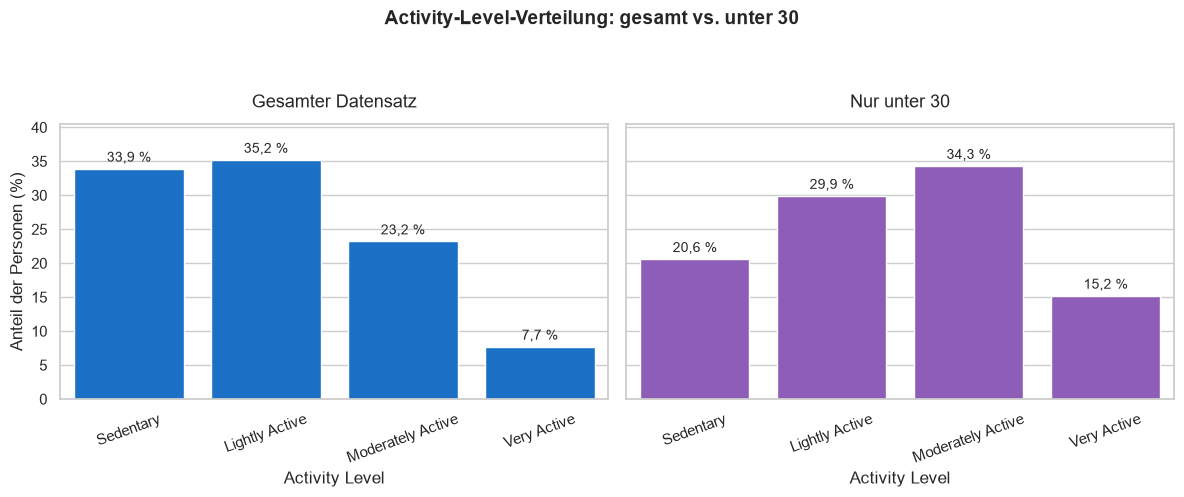

In [21]:
under30 = df[df['Age'] <= 29]
overall_pct = df['Activity_Level'].value_counts(normalize=True).mul(100).round(1)
under30_pct = under30['Activity_Level'].value_counts(normalize=True).mul(100).round(1)
comparison = pd.DataFrame({'Gesamt %': overall_pct, 'Unter 30 %': under30_pct}).reindex(activity_order)
print(comparison)

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
sns.barplot(x=overall_pct[activity_order].index, y=overall_pct[activity_order].values, order=activity_order,
            color=BLUE, ax=axes[0])
sns.barplot(x=under30_pct[activity_order].index, y=under30_pct[activity_order].values, order=activity_order,
            color=VIOLET, ax=axes[1])
finalize_plot(axes[0], 'Gesamter Datensatz', 'Activity Level', 'Anteil der Personen (%)')
finalize_plot(axes[1], 'Nur unter 30', 'Activity Level', 'Anteil der Personen (%)')
for a in axes:
    add_bar_labels(a, decimals=1, suffix=' %')
    a.tick_params(axis='x', rotation=20)
# Gesamttitel oberhalb der beiden Teilplot-Titel, mit Abstand (kein Überlappen)
fig.suptitle('Activity-Level-Verteilung: gesamt vs. unter 30', fontsize=14, fontweight='bold', y=0.99)
fig.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

**Interpretation:**

Die Aufschlüsselung der Unter-30-Gruppe (18–29, n = 9.524) zeigt ein deutlich anderes Aktivitätsprofil als der Datensatz insgesamt, und die Richtung ist über alle Kategorien hinweg konsistent, nicht nur bei einer einzelnen auffälligen Zahl. Sedentary sinkt von 33,9% insgesamt auf 20,6% in der jungen Gruppe — ein Sprung von 13 Punkten — während Very Active sich mehr als verdoppelt, von 7,7% auf 15,2%, und auch Moderately Active steigt (23,2% auf 34,3%) zulasten von Lightly Active. Insgesamt wirkt die Unter-30-Gruppe spürbar aktiver als die Gesamtpopulation, nicht nur geringfügig. Was dieser Vergleich nicht sagen kann, ist das *Warum*: Das ist eine einzelne Querschnitts-Momentaufnahme, keine Zeitreihe, also lässt sich nicht unterscheiden zwischen "Menschen werden mit dem Alter weniger aktiv" und "diese konkrete Stichprobe der Unter-30-Jährigen ist zufällig aktiver" — und Activity_Level ist selbstberichtet, es handelt sich also um einen Zusammenhang zwischen Alter und berichteter Aktivität, keinen Beweis für einen kausalen Lebensphasen-Effekt.